<a href="https://colab.research.google.com/github/321222/CLaude/blob/main/Credit_Card_fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Fraud Detection: Risk Analytics Project

This project implements a complete end-to-end Machine Learning pipeline for credit card fraud detection. It is designed to demonstrate key risk analytics competencies: handling highly imbalanced datasets, model optimization, metric-driven evaluation, and translating technical model outputs into actionable business value.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Generate a highly imbalanced synthetic fraud dataset for demonstration
np.random.seed(42)
n_samples = 50000
n_features = 5

# Normal transactions
normal_data = np.random.normal(loc=0, scale=1, size=(int(n_samples * 0.99), n_features))
normal_df = pd.DataFrame(normal_data, columns=[f'V{i}' for i in range(1, n_features + 1)])
normal_df['Amount'] = np.random.exponential(scale=50, size=len(normal_df))
normal_df['Class'] = 0

# Fraudulent transactions
fraud_data = np.random.normal(loc=1.5, scale=1.5, size=(int(n_samples * 0.01), n_features))
fraud_df = pd.DataFrame(fraud_data, columns=[f'V{i}' for i in range(1, n_features + 1)])
fraud_df['Amount'] = np.random.exponential(scale=120, size=len(fraud_df))
fraud_df['Class'] = 1

df = pd.concat([normal_df, fraud_df]).reset_index(drop=True)
print(f"Dataset generated: {df.shape[0]} rows, {df.shape[1]} columns.")
print(df['Class'].value_counts(normalize=True))

Dataset generated: 50000 rows, 7 columns.
Class
0    0.99
1    0.01
Name: proportion, dtype: float64


## 1. Exploratory Data Analysis (EDA)

We start by exploring the target distribution and checking feature distributions across classes to understand how fraud behaves compared to legitimate activities.

/tmp/ipykernel_3428/418866457.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette='Set2')


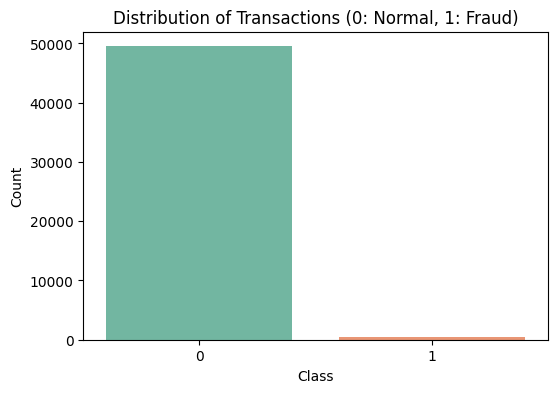

Transaction Counts:
Class
0    49500
1      500
Name: count, dtype: int64


/tmp/ipykernel_3428/418866457.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, palette='Set2')


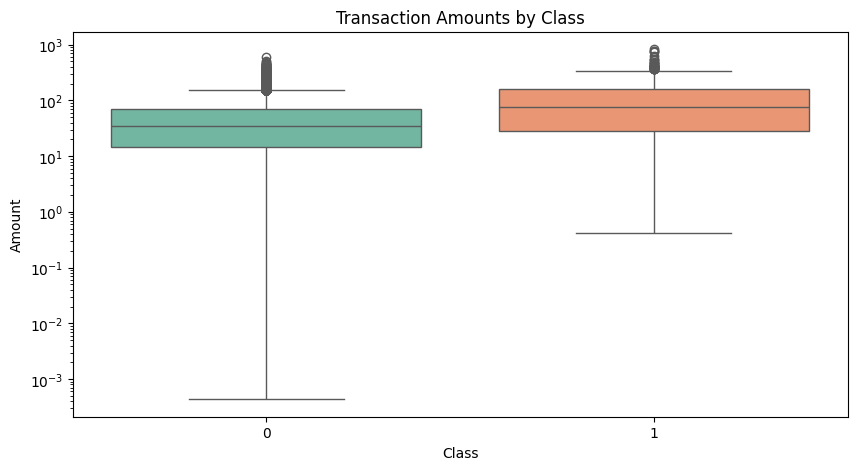

In [2]:
# Visualize class imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Distribution of Transactions (0: Normal, 1: Fraud)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

# Print the exact numbers
print("Transaction Counts:")
print(df['Class'].value_counts())

# Compare Amount distributed in Fraud vs Normal transactions
plt.figure(figsize=(10, 5))
sns.boxplot(x='Class', y='Amount', data=df, palette='Set2')
plt.title('Transaction Amounts by Class')
plt.yscale('log')
plt.show()

### Why Accuracy is Misleading in Fraud Detection

In our dataset, **99%** of the transactions are legitimate and only **1%** are fraudulent.

If we write a simple "dumb rule" model that classifies every single transaction as **Normal (0)**, that model would achieve **99% accuracy**. However, it would detect **0%** of actual fraud cases, resulting in massive financial losses and zero business value.

Therefore, we must evaluate our models using metrics that focus on correct detection of the positive class (Fraud): **Precision, Recall, F1-Score, and ROC-AUC**.

In [3]:
X = df.drop('Class', axis=1)
y = df['Class']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical attributes
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Apply SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# 2. Apply Undersampling
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)

print(f"Original training shape: {X_train.shape[0]} samples")
print(f"SMOTE training shape: {X_train_smote.shape[0]} samples")
print(f"Undersampled training shape: {X_train_rus.shape[0]} samples")

Original training shape: 40000 samples
SMOTE training shape: 79200 samples
Undersampled training shape: 800 samples


In [4]:
def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    print(f"=== {name} Performance ===")
    print(classification_report(y_test, preds))
    print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}\n")
    return preds, probs

# Logistic Regression models
lr_smote_preds, lr_smote_probs = evaluate_model(
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_smote, y_train_smote, X_test_scaled, y_test, "Logistic Regression (SMOTE)"
)

# Random Forest models
rf_smote_preds, rf_smote_probs = evaluate_model(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    X_train_smote, y_train_smote, X_test_scaled, y_test, "Random Forest (SMOTE)"
)

=== Logistic Regression (SMOTE) Performance ===
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      9900
           1       0.12      0.94      0.21       100

    accuracy                           0.93     10000
   macro avg       0.56      0.94      0.59     10000
weighted avg       0.99      0.93      0.96     10000

ROC-AUC Score: 0.9838

=== Random Forest (SMOTE) Performance ===
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      9900
           1       0.45      0.81      0.58       100

    accuracy                           0.99     10000
   macro avg       0.73      0.90      0.79     10000
weighted avg       0.99      0.99      0.99     10000

ROC-AUC Score: 0.9771



In [5]:
# Calculate confusion matrix values
cm = confusion_matrix(y_test, rf_smote_preds)
tn, fp, fn, tp = cm.ravel()
total_cases = len(y_test)
total_frauds = tp + fn

# Let's assume some realistic business costs:
# - Average cost of unchecked fraud: $250
# - Cost of manual review (false alarm): $15

caught_fraud_value = tp * 250
missed_fraud_cost = fn * 250
false_alarm_cost = fp * 15
net_savings = caught_fraud_value - (missed_fraud_cost + false_alarm_cost)

print("==========================================================")
print("         BUSINESS ANALYST RISK IMPACT SUMMARY             ")
print("==========================================================")
print(f"Total transactions analyzed: {total_cases}")
print(f"Actual fraud cases present:  {total_frauds}")
print(f"\n[+] Fraud Caught (True Positives): {tp} / {total_frauds} ({tp/total_frauds:.1%})")
print(f"[-] Fraud Missed (False Negatives): {fn} / {total_frauds} ({fn/total_frauds:.1%})")
print(f"[!] False Alarms Created (False Positives): {fp}")
print(f"\nPrecision: {tp/(tp+fp):.1%} of flagged alerts are real fraud.")
print(f"Recall:    {tp/(tp+fn):.1%} of all fraud cases are blocked.")
print("==========================================================")
print("                  FINANCIAL STATEMENT                     ")
print("==========================================================")
print(f"Estimated Fraud Losses Prevented:   ${caught_fraud_value:,.2f}")
print(f"Estimated Remaining Fraud Losses:  -${missed_fraud_cost:,.2f}")
print(f"Estimated Operational Review Cost: -${false_alarm_cost:,.2f}")
print(f"----------------------------------------------------------")
print(f"NET PROJECTED SAVINGS:             ${net_savings:,.2f}")
print("==========================================================")

         BUSINESS ANALYST RISK IMPACT SUMMARY             
Total transactions analyzed: 10000
Actual fraud cases present:  100

[+] Fraud Caught (True Positives): 81 / 100 (81.0%)
[-] Fraud Missed (False Negatives): 19 / 100 (19.0%)
[!] False Alarms Created (False Positives): 98

Precision: 45.3% of flagged alerts are real fraud.
Recall:    81.0% of all fraud cases are blocked.
                  FINANCIAL STATEMENT                     
Estimated Fraud Losses Prevented:   $20,250.00
Estimated Remaining Fraud Losses:  -$4,750.00
Estimated Operational Review Cost: -$1,470.00
----------------------------------------------------------
NET PROJECTED SAVINGS:             $14,030.00
